# Leakage-Safe Water Quality Index Forecasting

This notebook forecasts a river station's **next-year Water Quality Index (WQI)** from measurements available in the current year: pH, dissolved oxygen (DO), biochemical oxygen demand (BOD), total and fecal coliform counts, and nitrate. It uses the reusable implementation in `src/model.py`; no modeling logic is duplicated here.

Run this notebook from the repository root after `uv sync --group dev`.

## Research-paper context and project extension

The included paper (`paper/s12145-025-01865-2.pdf`) evaluates individual XGBR, RFR, SVR, and RNN models on 432 **monthly** Haridwar observations from 2017–2022, using an 80:20 split. Its reported R² values are 0.9128 (XGBR), 0.8927 (RFR), 0.9246 (SVR), and 0.9655 (RNN).

This repository contains 2003–2014 nationwide observations rather than that Haridwar dataset. LightGBM and the stacked ensemble are therefore project extensions. Paper scores are context for interpretation, not a target to optimize against.

## Why this is a forecast, not same-row fitting

WQI is calculated from water-quality measurements. Training on a WQI calculated from the *same row's* measurements would leak the answer into the inputs and can produce misleadingly high R². Instead, this notebook pairs a station's measurements at year *t* with its calculated WQI at year *t + 1*. Only consecutive-year station records are used.

Duplicate station/year rows are averaged. The documented five-input WQI approximation applies weights DO 0.31, pH 0.11, BOD 0.19, fecal coliform 0.28, and nitrate 0.11.

In [1]:
from pathlib import Path

import pandas as pd

from src.model import (
    FEATURE_COLUMNS,
    TEST_YEAR,
    TRAIN_END_YEAR,
    VALIDATION_YEAR,
    aggregate_station_years,
    apply_feature_engineering,
    build_forecast_pairs,
    generate_shap_summary,
    load_dataset,
    print_results,
    run_pipeline,
    split_by_target_year,
)

DATA_PATH = Path('data/dataset.csv')

## Prepare station-year forecast pairs

The target year controls every split: target years through 2012 form training, 2013 forms validation, and 2014 is the untouched final test set. Numeric imputation and scaling are fit inside the training flow only.

In [2]:
station_years = aggregate_station_years(load_dataset(DATA_PATH))
forecast_pairs = build_forecast_pairs(apply_feature_engineering(station_years))
partitions = split_by_target_year(forecast_pairs)

pd.DataFrame(
    {
        'partition': partitions.keys(),
        'target-year rule': [
            f'<= {TRAIN_END_YEAR}',
            str(VALIDATION_YEAR),
            str(TEST_YEAR),
        ],
        'forecast pairs': [len(partition) for partition in partitions.values()],
    }
)

,partition,target-year rule,forecast pairs
0,train,<= 2012,707
1,validation,2013,228
2,test,2014,220


## Benchmark models and generalization checks

The benchmark evaluates median and persistence baselines, Random Forest, XGBoost, LightGBM, SVR, and a Ridge meta-model stacked from chronological out-of-fold base-model predictions. The stack never uses random cross-validation or test labels.

Metrics are R², MAE, RMSE, and MSE. A train-to-validation R² drop above 0.10 is reported as an overfitting warning; model choices should be made from validation metrics before reading the final test results.

In [3]:
results = run_pipeline(DATA_PATH)
print_results(results)

metric_table = pd.concat(
    {partition: pd.DataFrame(metrics).T for partition, metrics in results.items()},
    names=['partition', 'model'],
).round(4)
metric_table


Train metrics
  random_forest          R2=0.9430  MAE=2.3870  RMSE=3.3058  MSE=10.9283
  xgboost                R2=0.9640  MAE=1.9821  RMSE=2.6254  MSE=6.8928
  lightgbm               R2=0.9427  MAE=2.4912  RMSE=3.3145  MSE=10.9856
  svr                    R2=0.7959  MAE=4.4903  RMSE=6.2557  MSE=39.1336
  median_baseline        R2=-0.0722  MAE=9.4793  RMSE=14.3371  MSE=205.5518
  persistence_baseline   R2=0.8383  MAE=3.9373  RMSE=5.5681  MSE=31.0041
  stacked_ensemble       R2=0.9271  MAE=2.8113  RMSE=3.7385  MSE=13.9762

Validation metrics
  random_forest          R2=0.8513  MAE=3.8790  RMSE=5.1678  MSE=26.7057
  xgboost                R2=0.8497  MAE=3.7723  RMSE=5.1956  MSE=26.9941
  lightgbm               R2=0.8600  MAE=3.6774  RMSE=5.0135  MSE=25.1351
  svr                    R2=0.8338  MAE=4.0938  RMSE=5.4625  MSE=29.8388
  median_baseline        R2=-0.0786  MAE=9.0126  RMSE=13.9175  MSE=193.6971
  persistence_baseline   R2=0.8790  MAE=3.2872  RMSE=4.6623  MSE=21.7370
  stacked_e

r2     mae     rmse       mse
partition  model                                                  
train      random_forest         0.9430  2.3870   3.3058   10.9283
           xgboost               0.9640  1.9821   2.6254    6.8928
           lightgbm              0.9427  2.4912   3.3145   10.9856
           svr                   0.7959  4.4903   6.2557   39.1336
           median_baseline      -0.0722  9.4793  14.3371  205.5518
           persistence_baseline  0.8383  3.9373   5.5681   31.0041
           stacked_ensemble      0.9271  2.8113   3.7385   13.9762
validation random_forest         0.8513  3.8790   5.1678   26.7057
           xgboost               0.8497  3.7723   5.1956   26.9941
           lightgbm              0.8600  3.6774   5.0135   25.1351
           svr                   0.8338  4.0938   5.4625   29.8388
           median_baseline      -0.0786  9.0126  13.9175  193.6971
           persistence_baseline  0.8790  3.2872   4.6623   21.7370
           stacked_ensemble      0.8552  3.7951   5.0990   26.0003
test       random_forest         0.8648  3.9590   5.2389   27.4460
           xgboost               0.8536  3.9979   5.4503   29.7062
           lightgbm              0.8521  4.0291   5.4795   30.0245
           svr                   0.7517  5.0512   7.0992   50.3988
           median_baseline      -0.0988  9.5149  14.9329  222.9918
           persistence_baseline  0.9076  3.1405   4.3294   18.7440
           stacked_ensemble      0.8560  4.0055   5.4056   29.2210

## SHAP explainability

SHAP explains the fitted Random Forest on held-out test samples. It describes feature influence in this model; it does not establish causation. The output path is explicit so generated artifacts stay outside the repository unless intentionally saved elsewhere.

In [4]:
shap_output = Path('/tmp/wqi-random-forest-shap.png')
generate_shap_summary(DATA_PATH, shap_output)
shap_output

WindowsPath('/tmp/wqi-random-forest-shap.png')

## RNN: deferred until sequence validation

The research paper's RNN is appropriate for its monthly time series. This data is annual with irregular station histories, so an RNN is intentionally not included in the current benchmark. Implement it only after choosing and testing a sequence length, handling missing years, and ensuring all historical windows precede their targets. Install the optional dependency when needed with `uv sync --group rnn`.

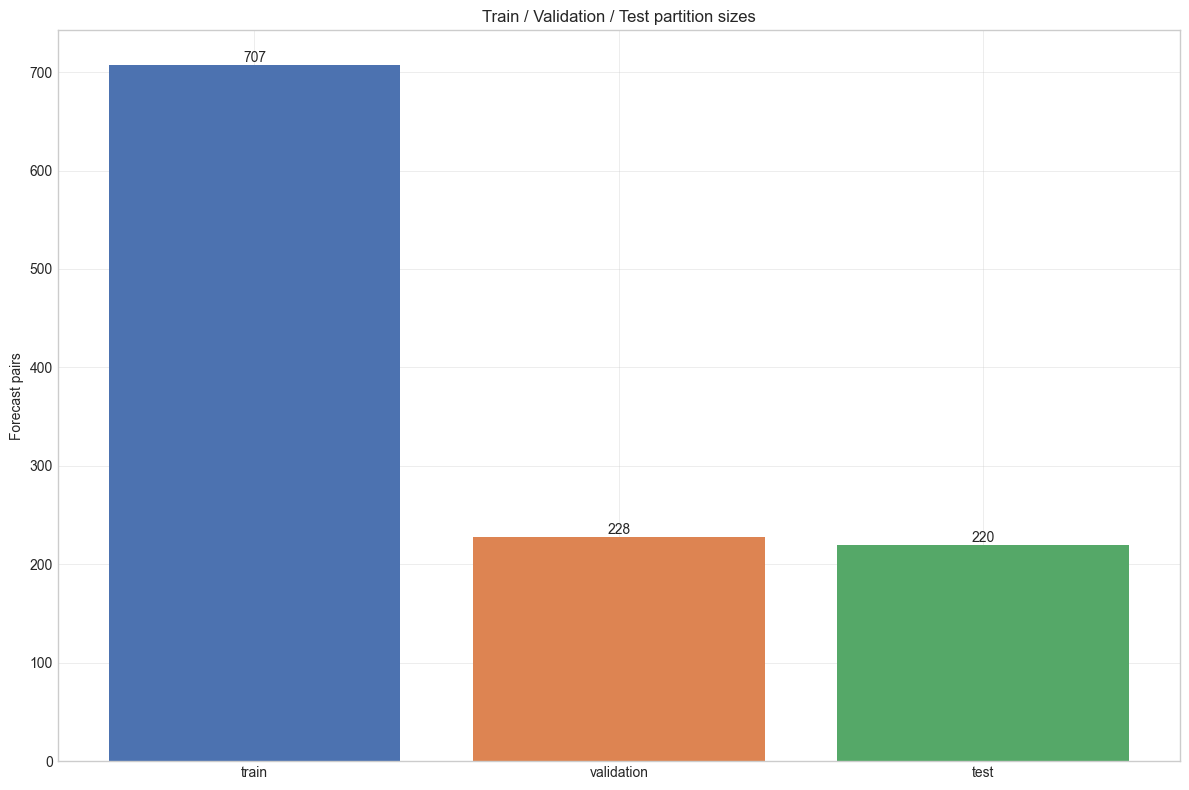

In [5]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

# 1. Partition sizes — train/val/test split balance
fig, ax = plt.subplots(figsize=(12, 8))
partition_names = list(partitions.keys())
partition_sizes = [len(p) for p in partitions.values()]
ax.bar(partition_names, partition_sizes, color=['#4C72B0', '#DD8452', '#55A868'])
ax.set_ylabel('Forecast pairs')
ax.set_title('Train / Validation / Test partition sizes')
for i, v in enumerate(partition_sizes):
    ax.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout()
plt.savefig('assets/partition_sizes.png', dpi=150)
plt.show()

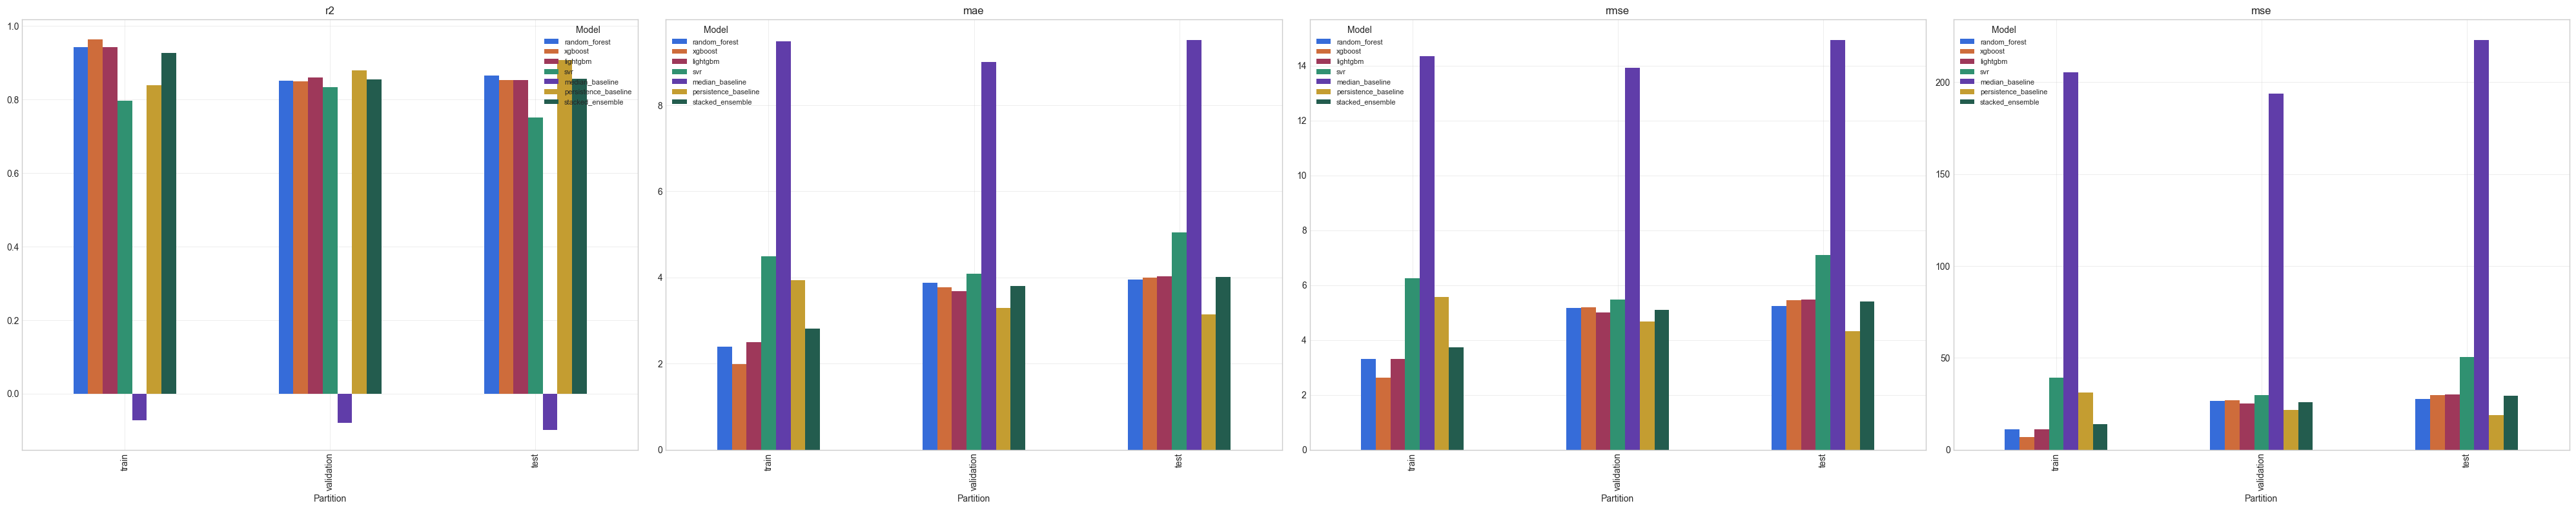

In [6]:
# 2. Model comparison across partitions, per metric
metrics_available = metric_table.columns.tolist()
n_metrics = len(metrics_available)

fig, axes = plt.subplots(1, n_metrics, figsize=(10 * n_metrics, 8))
if n_metrics == 1:
    axes = [axes]

for ax, metric in zip(axes, metrics_available):
    pivoted = metric_table[metric].unstack('model')
    pivoted.plot(kind='bar', ax=ax)
    ax.set_title(metric)
    ax.set_xlabel('Partition')
    ax.legend(title='Model', fontsize=8)

plt.tight_layout()
plt.savefig('assets/model_comparison_metrics.png', dpi=150)
plt.show()


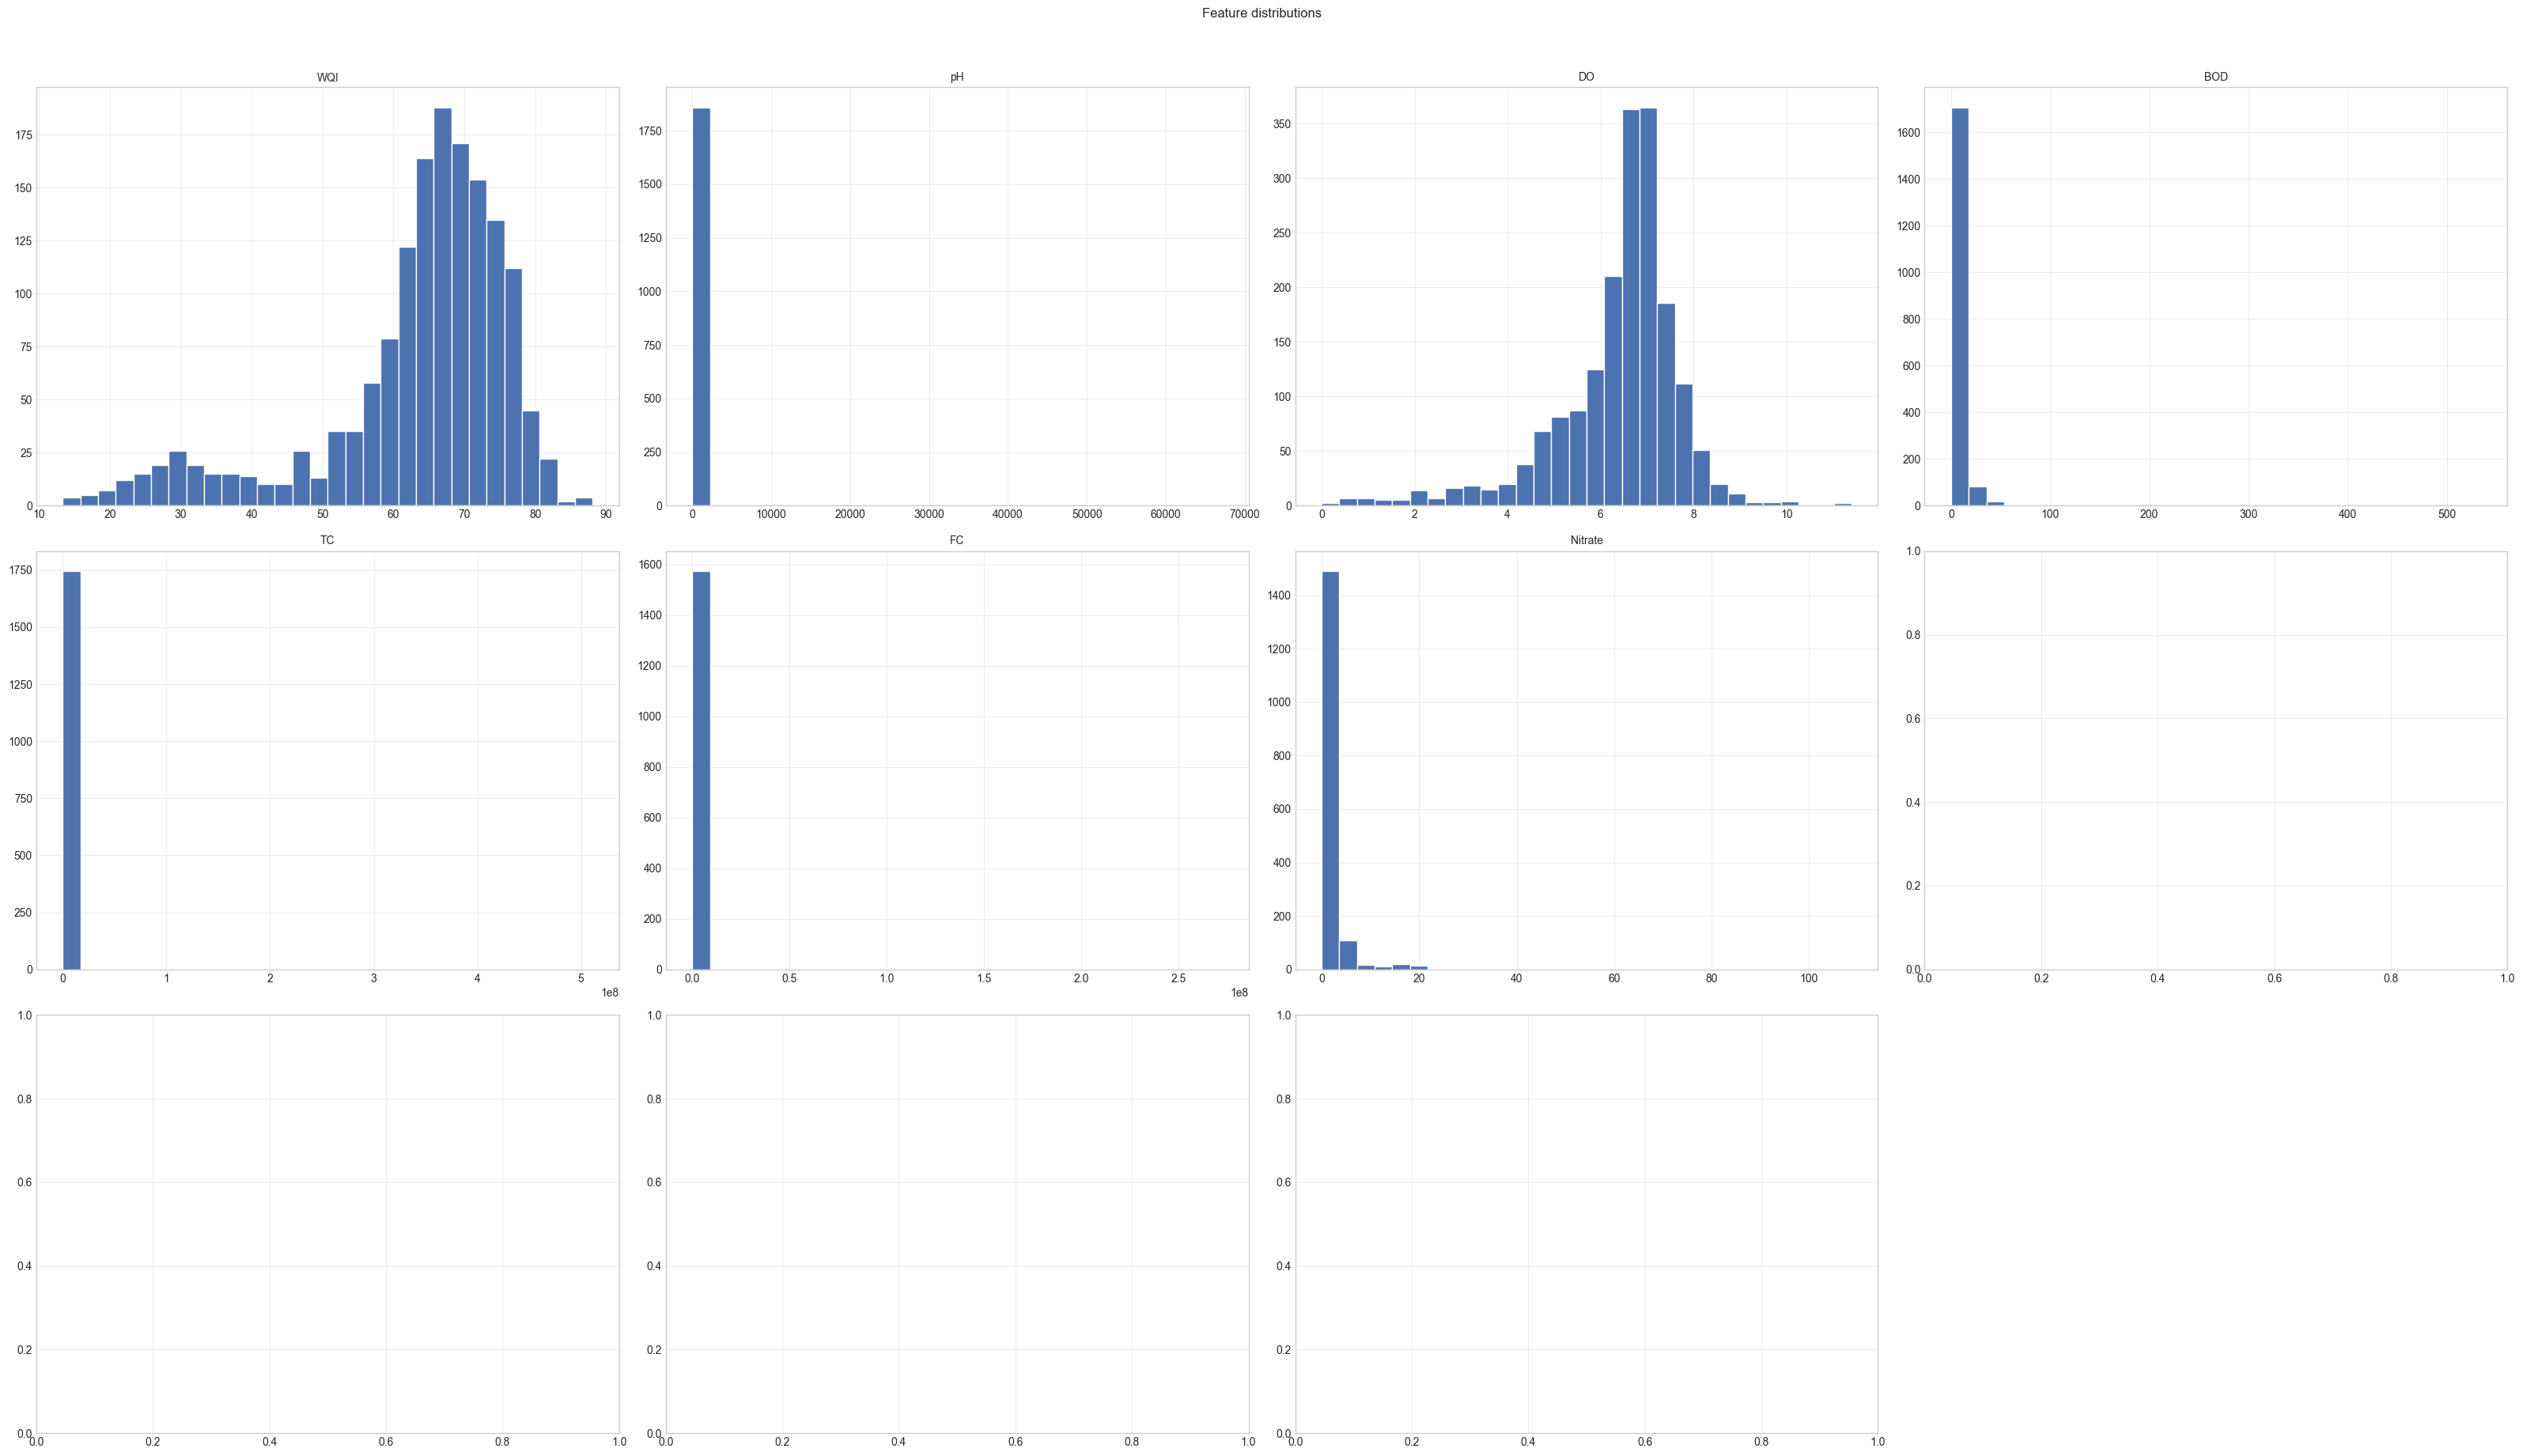

In [7]:
# 3. Feature distributions across the dataset
n_features = len(FEATURE_COLUMNS)
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 6 * n_rows))
axes = axes.flatten()

for i, col in enumerate(FEATURE_COLUMNS):
    if col in station_years.columns:
        axes[i].hist(station_years[col].dropna(), bins=30, color='#4C72B0', edgecolor='white')
        axes[i].set_title(col, fontsize=10)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Feature distributions', y=1.02)
plt.tight_layout()
plt.savefig('assets/feature_distributions.png', dpi=150)
plt.show()

C:\Users\Ayush\AppData\Local\Temp\ipykernel_22248\1379956560.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


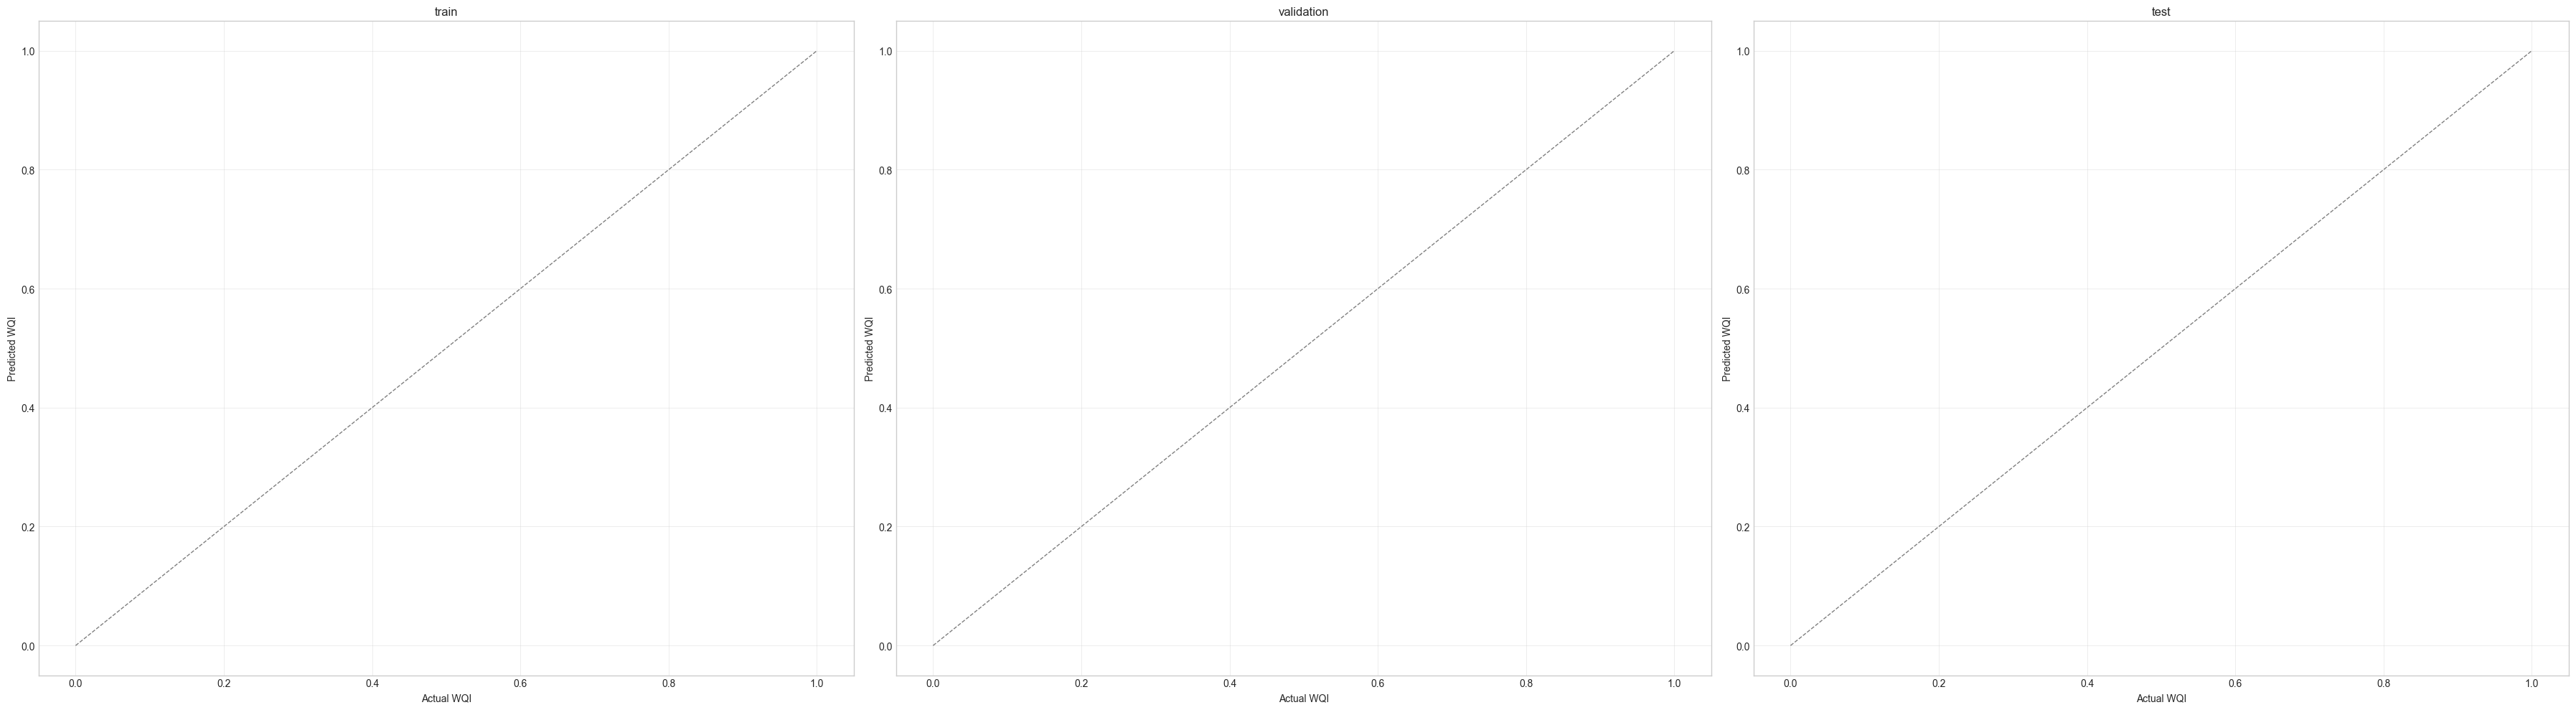

In [8]:
# 4. Actual vs predicted
fig, axes = plt.subplots(1, len(partitions), figsize=(12 * len(partitions), 10))

for ax, (partition_name, models) in zip(axes, results.items()):
    for model_name, metrics in models.items():
        if 'y_true' in metrics and 'y_pred' in metrics:
            ax.scatter(metrics['y_true'], metrics['y_pred'], alpha=0.5, label=model_name, s=15)
    ax.set_xlabel('Actual WQI')
    ax.set_ylabel('Predicted WQI')
    ax.set_title(partition_name)
    ax.legend(fontsize=8)
    lims = [ax.get_xlim(), ax.get_ylim()]
    lo, hi = min(l[0] for l in lims), max(l[1] for l in lims)
    ax.plot([lo, hi], [lo, hi], 'k--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.savefig('assets/actual_vs_predicted.png', dpi=150)
plt.show()

In [9]:
station_years = aggregate_station_years(load_dataset(DATA_PATH))
forecast_pairs = build_forecast_pairs(apply_feature_engineering(station_years))
partitions = split_by_target_year(forecast_pairs)
pd.DataFrame(
    {
        'partition': partitions.keys(),
        'target-year rule': [
            f'<= {TRAIN_END_YEAR}',
            str(VALIDATION_YEAR),
            str(TEST_YEAR),
        ],
        'forecast pairs': [len(partition) for partition in partitions.values()],
    }
)

,partition,target-year rule,forecast pairs
0,train,<= 2012,707
1,validation,2013,228
2,test,2014,220


In [10]:
results = run_pipeline(DATA_PATH)
print_results(results)
metric_table = pd.concat(
    {partition: pd.DataFrame(metrics).T for partition, metrics in results.items()},
    names=['partition', 'model'],
).round(4)
metric_table


Train metrics
  random_forest          R2=0.9430  MAE=2.3870  RMSE=3.3058  MSE=10.9283
  xgboost                R2=0.9640  MAE=1.9821  RMSE=2.6254  MSE=6.8928
  lightgbm               R2=0.9427  MAE=2.4912  RMSE=3.3145  MSE=10.9856
  svr                    R2=0.7959  MAE=4.4903  RMSE=6.2557  MSE=39.1336
  median_baseline        R2=-0.0722  MAE=9.4793  RMSE=14.3371  MSE=205.5518
  persistence_baseline   R2=0.8383  MAE=3.9373  RMSE=5.5681  MSE=31.0041
  stacked_ensemble       R2=0.9271  MAE=2.8113  RMSE=3.7385  MSE=13.9762

Validation metrics
  random_forest          R2=0.8513  MAE=3.8790  RMSE=5.1678  MSE=26.7057
  xgboost                R2=0.8497  MAE=3.7723  RMSE=5.1956  MSE=26.9941
  lightgbm               R2=0.8600  MAE=3.6774  RMSE=5.0135  MSE=25.1351
  svr                    R2=0.8338  MAE=4.0938  RMSE=5.4625  MSE=29.8388
  median_baseline        R2=-0.0786  MAE=9.0126  RMSE=13.9175  MSE=193.6971
  persistence_baseline   R2=0.8790  MAE=3.2872  RMSE=4.6623  MSE=21.7370
  stacked_e

r2     mae     rmse       mse
partition  model                                                  
train      random_forest         0.9430  2.3870   3.3058   10.9283
           xgboost               0.9640  1.9821   2.6254    6.8928
           lightgbm              0.9427  2.4912   3.3145   10.9856
           svr                   0.7959  4.4903   6.2557   39.1336
           median_baseline      -0.0722  9.4793  14.3371  205.5518
           persistence_baseline  0.8383  3.9373   5.5681   31.0041
           stacked_ensemble      0.9271  2.8113   3.7385   13.9762
validation random_forest         0.8513  3.8790   5.1678   26.7057
           xgboost               0.8497  3.7723   5.1956   26.9941
           lightgbm              0.8600  3.6774   5.0135   25.1351
           svr                   0.8338  4.0938   5.4625   29.8388
           median_baseline      -0.0786  9.0126  13.9175  193.6971
           persistence_baseline  0.8790  3.2872   4.6623   21.7370
           stacked_ensemble      0.8552  3.7951   5.0990   26.0003
test       random_forest         0.8648  3.9590   5.2389   27.4460
           xgboost               0.8536  3.9979   5.4503   29.7062
           lightgbm              0.8521  4.0291   5.4795   30.0245
           svr                   0.7517  5.0512   7.0992   50.3988
           median_baseline      -0.0988  9.5149  14.9329  222.9918
           persistence_baseline  0.9076  3.1405   4.3294   18.7440
           stacked_ensemble      0.8560  4.0055   5.4056   29.2210

In [11]:
from hybrid_model import run_hybrid_pipeline, print_hybrid_results
results = run_hybrid_pipeline('data/dataset.csv')
print_hybrid_results(results)


Train metrics
  random_forest    R2=0.9430  MAE=2.3870  RMSE=3.3058  MSE=10.9283
  xgboost          R2=0.9640  MAE=1.9821  RMSE=2.6254  MSE=6.8928
  weighted_blend   R2=0.9539  MAE=2.1892  RMSE=2.9712  MSE=8.8282
  stacked_blend    R2=0.9435  MAE=2.3736  RMSE=3.2921  MSE=10.8380

Validation metrics
  random_forest    R2=0.8513  MAE=3.8790  RMSE=5.1678  MSE=26.7057
  xgboost          R2=0.8497  MAE=3.7723  RMSE=5.1956  MSE=26.9941
  weighted_blend   R2=0.8533  MAE=3.7877  RMSE=5.1320  MSE=26.3371
  stacked_blend    R2=0.8460  MAE=3.9631  RMSE=5.2581  MSE=27.6478

Test metrics
  random_forest    R2=0.8648  MAE=3.9590  RMSE=5.2389  MSE=27.4460
  xgboost          R2=0.8536  MAE=3.9979  RMSE=5.4503  MSE=29.7062
  weighted_blend   R2=0.8629  MAE=3.9417  RMSE=5.2742  MSE=27.8176
  stacked_blend    R2=0.8632  MAE=3.9919  RMSE=5.2694  MSE=27.7664

Weighted blend weight on RF: 0.57 (XGB gets 0.43)
Stacked blend coefficients: {'random_forest': np.float64(1.0021774367927492), 'xgboost': np.float6